In [53]:
from langgraph.graph import StateGraph, START, END
from typing import TypedDict, Annotated
from langchain_google_genai import ChatGoogleGenerativeAI
from langchain_core.messages import BaseMessage, HumanMessage
# from langchain_groq import ChatGroq
from langgraph.graph.message import add_messages
from dotenv import load_dotenv
from langgraph.prebuilt import ToolNode, tools_condition
from langchain_tavily import TavilySearch
from langchain_core.tools import tool
from typing import Any
import requests
import math
import os

In [54]:
load_dotenv()


True

In [55]:
# llm = ChatGroq(
#     model="openai/gpt-oss-20b",
#     temperature=0
# )
# The client automatically picks up os.environ["GOOGLE_API_KEY"]
llm = ChatGoogleGenerativeAI(
    model="gemini-3-flash-preview",
    temperature=0.3,
)

In [56]:
# Tools
search_tool = TavilySearch(
    max_results=5,
    topic="general",
    search_depth="advanced"
)



@tool
def calculator(expression: str) -> str:
    """
    Useful for simple math calculations.
    Input should be a valid math expression.
    Example: 2 + 2, math.sqrt(16), 10 * 5
    """

    try:
        allowed = {
            "math": math,
            "abs": abs,
            "round": round,
            "min": min,
            "max": max,
            "sum": sum
        }

        result = eval(expression, {"__builtins__": {}}, allowed)
        return str(result)

    except Exception as e:
        return f"Calculation error: {str(e)}"


@tool
def get_stock_price(symbol: str) -> dict:
    """
    Fetch latest stock price for a given symbol (e.g. 'AAPL', 'TSLA') 
    using Alpha Vantage with API key in the URL.
    """
    api_key = os.getenv("ALPHA_VANTAGE_API_KEY")
    if not api_key:
        raise ValueError("Alpha Vantage API key is missing from the .env file")
    url = f"https://www.alphavantage.co/query?function=GLOBAL_QUOTE&symbol={symbol}&apikey={api_key}"
    r = requests.get(url)
    return r.json()



@tool
def get_current_weather(location: str) -> str:
    """
    Get the current real-time weather for a given city or location.

    Args:
        location: City or location name, for example:
                  "Dhaka", "London, UK", or "New York, US".

    Returns:
        A formatted current weather report.
    """

    api_key = os.getenv("OPENWEATHER_API_KEY")

    if not api_key:
        return (
            "Weather API key is missing. "
            "Set the OPENWEATHER_API_KEY environment variable."
        )

    try:
        # Step 1: Convert the location name into latitude and longitude
        geocoding_url = "https://api.openweathermap.org/geo/1.0/direct"

        geocoding_params = {
            "q": location,
            "limit": 1,
            "appid": api_key,
        }

        geo_response = requests.get(
            geocoding_url,
            params=geocoding_params,
            timeout=10,
        )
        geo_response.raise_for_status()

        locations: list[dict[str, Any]] = geo_response.json()

        if not locations:
            return f"Could not find the location: {location}"

        latitude = locations[0]["lat"]
        longitude = locations[0]["lon"]
        resolved_name = locations[0].get("name", location)
        country = locations[0].get("country", "")
        state = locations[0].get("state", "")

        # Step 2: Get current weather using latitude and longitude
        weather_url = "https://api.openweathermap.org/data/2.5/weather"

        weather_params = {
            "lat": latitude,
            "lon": longitude,
            "appid": api_key,
            "units": "metric",
        }

        weather_response = requests.get(
            weather_url,
            params=weather_params,
            timeout=10,
        )
        weather_response.raise_for_status()

        weather_data = weather_response.json()

        temperature = weather_data["main"]["temp"]
        feels_like = weather_data["main"]["feels_like"]
        humidity = weather_data["main"]["humidity"]
        pressure = weather_data["main"]["pressure"]
        description = weather_data["weather"][0]["description"]
        wind_speed = weather_data.get("wind", {}).get("speed", "N/A")
        visibility_meters = weather_data.get("visibility")

        visibility_km = (
            round(visibility_meters / 1000, 1)
            if visibility_meters is not None
            else "N/A"
        )

        location_parts = [resolved_name]

        if state:
            location_parts.append(state)

        if country:
            location_parts.append(country)

        display_location = ", ".join(location_parts)

        return (
            f"Current weather in {display_location}:\n"
            f"- Condition: {description.title()}\n"
            f"- Temperature: {temperature}°C\n"
            f"- Feels like: {feels_like}°C\n"
            f"- Humidity: {humidity}%\n"
            f"- Pressure: {pressure} hPa\n"
            f"- Wind speed: {wind_speed} m/s\n"
            f"- Visibility: {visibility_km} km"
        )

    except requests.Timeout:
        return "The weather service request timed out. Please try again."

    except requests.HTTPError as error:
        status_code = error.response.status_code if error.response else "unknown"

        if status_code == 401:
            return "The OpenWeather API key is invalid or inactive."

        return f"Weather API returned an HTTP error: {status_code}"

    except requests.RequestException as error:
        return f"Could not connect to the weather service: {error}"

    except (KeyError, TypeError, ValueError) as error:
        return f"Unexpected weather API response: {error}"

In [57]:
# Make tool list
tools = [search_tool,calculator, get_stock_price,get_current_weather]

# Make the LLM tool-aware
llm_with_tools = llm.bind_tools(tools)

In [58]:
# state
class ChatState(TypedDict):
    messages: Annotated[list[BaseMessage], add_messages]

In [59]:
# graph nodes
def chat_node(state: ChatState):
    """LLM node that may answer or request a tool call."""
    messages = state['messages']
    response = llm_with_tools.invoke(messages)
    return {"messages": [response]}

tool_node = ToolNode(tools)  # Executes tool calls

In [60]:
# graph structure
graph = StateGraph(ChatState)
graph.add_node("chat_node", chat_node)
graph.add_node("tools", tool_node)

In [61]:
graph.add_edge(START, "chat_node")

# If the LLM asked for a tool, go to ToolNode; else finish
graph.add_conditional_edges("chat_node", tools_condition)

graph.add_edge("tools", "chat_node")
# graph.add_edge("chat_node", END)

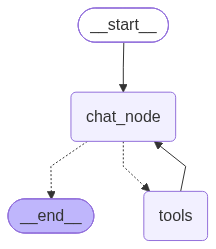

In [39]:
chatbot = graph.compile()

chatbot

In [40]:
# Regular chat
out = chatbot.invoke({"messages": [HumanMessage(content="Hello!")]})

print(out["messages"][-1].content)

[{'type': 'text', 'text': 'Hello! How can I help you today?', 'extras': {'signature': 'Eo8CCowCAWkUfRPzXKFR4nW6SQd9s6MIyy6VUqHOIM3KmrhIx4GwKEMCZKcRJkg8jC+aGnk/48L9CLNyap9xAfWwf8EhU6LnLBUMggvxddNEIwWf176+VJ70w7O/0W/oEhQKWukiZB8HCmb0KsF6MV+S16QteDV25xXxNg30CftoxnxFRs85nsK6rFVyMDddzr6wjGpIJIDIFuzoBDMdma4IlaPc2xftD6P5LevlAQEBHDU8CcRmAsNFqPbk0eOdP82G/Tu6l3l3F6vU23xFPakif9W1a0wRr5Y4V3Hogb8E9JxJIzHeMLlX7XnKHSYTDQ79Iw8iqlk/hMwsiUZF2SltPT/6UMcf9Hll6CxT2DwMpw=='}}]


In [48]:
# Chat requiring tool
out = chatbot.invoke({"messages": [HumanMessage(content="What is 8989898*90909090+5404040?")]})
print(out["messages"][-1].content[0]["text"])


817,263,451,776,860


In [49]:
# Chat requiring tool
out = chatbot.invoke({"messages": [HumanMessage(content="what is the new movie releases in 2026")]})
print(out["messages"][-1].content[0]["text"])

ChatGoogleGenerativeAIError: Error calling model 'gemini-3-flash-preview' (RESOURCE_EXHAUSTED): 429 RESOURCE_EXHAUSTED. {'error': {'code': 429, 'message': 'You exceeded your current quota, please check your plan and billing details. For more information on this error, head to: https://ai.google.dev/gemini-api/docs/rate-limits. To monitor your current usage, head to: https://ai.dev/rate-limit. \n* Quota exceeded for metric: generativelanguage.googleapis.com/generate_content_free_tier_requests, limit: 20, model: gemini-3-flash, description: Generate content requests per day limit exceeded on Free Tier. See https://ai.google.dev/gemini-api/docs/rate-limits.\nPlease retry in 13m20.911469599s.', 'status': 'RESOURCE_EXHAUSTED', 'details': [{'@type': 'type.googleapis.com/google.rpc.Help', 'links': [{'description': 'Learn more about Gemini API quotas', 'url': 'https://ai.google.dev/gemini-api/docs/rate-limits'}]}, {'@type': 'type.googleapis.com/google.rpc.QuotaFailure', 'violations': [{'descri

In [43]:
print(out["messages"][-1].content[0]['text'])


The year 2026 is shaping up to be a massive year for cinema, featuring highly anticipated sequels, major franchise expansions (Marvel, Star Wars, DC), and new projects from acclaimed directors like Christopher Nolan and Robert Eggers.

Below are the most notable movie releases currently scheduled for 2026, categorized by their release windows.

### **Spring 2026**
*   **Scream 7** (February 27): Neve Campbell returns as Sidney Prescott in the latest installment of the slasher franchise.
*   **Hoppers** (March 6): A new original film from Disney and Pixar about a girl who "hops" her mind into a robotic beaver to go undercover in the animal world.
*   **The Bride!** (March 6): Directed by Maggie Gyllenhaal, this reimagining of *The Bride of Frankenstein* stars Christian Bale and Jessie Buckley.
*   **Reminders of Him** (March 13): An adaptation of the Colleen Hoover bestseller.

### **Summer 2026 (Blockbuster Season)**
*   **Mortal Kombat II** (May 8): The sequel to the 2021 reboot, feat

In [ ]:
# Chat requiring tool
out = chatbot.invoke({"messages": [HumanMessage(content="First find out the stock price of Apple using get stock price tool then use the calculator tool to find out how much will it take to purchase 50 shares?")]})
print(out["messages"][-1].content[0]['text'])

[{'type': 'text', 'text': 'The current stock price of Apple (AAPL) is $347.10. To purchase 50 shares, it would cost $17,355.00.'}]


In [45]:
print(out["messages"][-1].content[0]['text'])


The current stock price of Apple (AAPL) is $347.10. To purchase 50 shares, it would cost $17,355.00.


In [46]:
# Chat requiring tool
out = chatbot.invoke({"messages": [HumanMessage(content="What is the current weather in New York?")]})
print(out["messages"][-1].content)

[{'type': 'text', 'text': 'The current weather in New York is clear with a temperature of 5.8°C (42.4°F). It feels like 5°C (41°F), and the humidity is at 80%. There is a light breeze of 1.39 m/s.'}]


In [47]:
print(out["messages"][-1].content[0]['text'])


The current weather in New York is clear with a temperature of 5.8°C (42.4°F). It feels like 5°C (41°F), and the humidity is at 80%. There is a light breeze of 1.39 m/s.
